# Programming Assignments – Natural Language Processing

Complete implementations for all five assignments:
1. Sentence similarity (TF–IDF/cosine) and word associations (PMI/PPMI).
2. Sentiment polarity and emotion detection using lexicons.
3. Indian-language-to-English translation using a pretrained multilingual model.
4. College task-oriented chatbot with intent recognition and dialogue state.
5. Multilingual ASR and log-Mel spectrogram visualization.

## 0. Install and import core libraries

In [ ]:
!pip install numpy pandas scikit-learn matplotlib seaborn nltk

In [ ]:
import re, math, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
print("Core libraries imported successfully.")

Core libraries imported successfully.


---
# Assignment 1 – Sentence Similarity and Word Associations

**TF–IDF** weights terms by their importance in a document collection. **Cosine similarity** compares vector direction (1 means identical direction; 0 means orthogonal). **PMI** measures whether two words co-occur more often than expected by chance:

\(PMI(w_1,w_2)=\log_2\frac{P(w_1,w_2)}{P(w_1)P(w_2)}\)

**PPMI** is \(\max(PMI,0)\). This implementation counts word pairs within a symmetric context window.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sentences = [
    "Machine learning helps computers learn patterns from data.",
    "Artificial intelligence uses data to make intelligent decisions.",
    "Deep learning is a branch of machine learning.",
    "The library provides books and study resources to students.",
    "Students borrow books from the college library."
]

vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = vectorizer.fit_transform(sentences)
similarity_matrix = cosine_similarity(tfidf_matrix)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
display(pd.DataFrame(similarity_matrix,
    index=[f"S{i+1}" for i in range(len(sentences))],
    columns=[f"S{i+1}" for i in range(len(sentences))]).round(3))

def compare_sentences(sentence_a, sentence_b):
    # Use the same fitted vocabulary so both sentences share a feature space.
    vectors = vectorizer.transform([sentence_a, sentence_b])
    return float(cosine_similarity(vectors[0], vectors[1])[0, 0])

print("Example similarity:",
      round(compare_sentences("Machine learning finds patterns in data.",
                              "Deep learning is related to machine learning."), 4))

TF-IDF matrix shape: (5, 23)


,S1,S2,S3,S4,S5
S1,1.000,0.103,0.349,0.000,0.000
S2,0.103,1.000,0.000,0.000,0.000
S3,0.349,0.000,1.000,0.000,0.000
S4,0.000,0.000,0.000,1.000,0.441
S5,0.000,0.000,0.000,0.441,1.000


Example similarity: 0.5509


In [ ]:
# Find the most similar pair, excluding each sentence's similarity with itself.
best_pair, best_score = None, -1
for i in range(len(sentences)):
    for j in range(i + 1, len(sentences)):
        if similarity_matrix[i, j] > best_score:
            best_pair, best_score = (i, j), similarity_matrix[i, j]
print("Most similar pair:")
print("S{}: {}".format(best_pair[0]+1, sentences[best_pair[0]]))
print("S{}: {}".format(best_pair[1]+1, sentences[best_pair[1]]))
print("Cosine similarity:", round(float(best_score), 4))

Most similar pair:
S4: The library provides books and study resources to students.
S5: Students borrow books from the college library.
Cosine similarity: 0.4413


### PMI and PPMI word associations

Tokenization removes punctuation and lowercases words. Each unordered pair within the context window is counted once for each occurrence. Use a larger corpus for more meaningful associations.

In [ ]:
association_corpus = [
    "machine learning uses data to learn patterns",
    "deep learning is a type of machine learning",
    "students use the library to read books",
    "the library has books and study resources",
    "data science uses machine learning methods",
    "students learn computer science and data science"
]

def tokenize(text):
    return re.findall(r"\b[a-z]+\b", text.lower())

def calculate_pmi(corpus, window_size=2, min_pair_count=1):
    unigram_counts, pair_counts = Counter(), Counter()
    total_tokens = 0

    for document in corpus:
        tokens = tokenize(document)
        unigram_counts.update(tokens)
        total_tokens += len(tokens)
        for i, word in enumerate(tokens):
            for j in range(i + 1, min(i + window_size + 1, len(tokens))):
                other = tokens[j]
                if word != other:
                    pair_counts[tuple(sorted((word, other)))] += 1

    total_pairs = sum(pair_counts.values())
    if total_tokens == 0 or total_pairs == 0:
        raise ValueError("Corpus must contain enough tokens to form word pairs.")

    # Use one consistent sample space: all observed pair events.
    # Each pair event contributes one occurrence to each endpoint marginal.
    endpoint_counts = Counter()
    for (w1, w2), count in pair_counts.items():
        endpoint_counts[w1] += count
        endpoint_counts[w2] += count

    rows = []
    for (w1, w2), count in pair_counts.items():
        if count < min_pair_count:
            continue
        p_w1 = endpoint_counts[w1] / (2 * total_pairs)
        p_w2 = endpoint_counts[w2] / (2 * total_pairs)
        p_pair = count / total_pairs
        pmi = math.log2(p_pair / (p_w1 * p_w2))
        rows.append({"word_1": w1, "word_2": w2,
                     "cooccurrence_count": count,
                     "PMI": pmi, "PPMI": max(pmi, 0.0)})

    return pd.DataFrame(rows).sort_values(
        ["PPMI", "cooccurrence_count"], ascending=False
    ).reset_index(drop=True)
pmi_results = calculate_pmi(association_corpus, window_size=2)
display(pmi_results.head(15).round(4))
print("Top positive associations:")
display(pmi_results[pmi_results.PPMI > 0].head(10).round(4))

,word_1,word_2,cooccurrence_count,PMI,PPMI
0,resources,study,1,5.4594,5.4594
1,deep,is,1,5.0444,5.0444
2,learn,patterns,1,4.4594,4.4594
3,students,use,1,4.4594,4.4594
4,patterns,to,1,4.0444,4.0444
5,a,is,1,4.0444,4.0444
6,is,type,1,4.0444,4.0444
7,a,type,1,4.0444,4.0444
8,a,of,1,4.0444,4.0444
9,of,type,1,4.0444,4.0444


Top positive associations:


,word_1,word_2,cooccurrence_count,PMI,PPMI
0,resources,study,1,5.4594,5.4594
1,deep,is,1,5.0444,5.0444
2,learn,patterns,1,4.4594,4.4594
3,students,use,1,4.4594,4.4594
4,patterns,to,1,4.0444,4.0444
5,a,is,1,4.0444,4.0444
6,is,type,1,4.0444,4.0444
7,a,type,1,4.0444,4.0444
8,a,of,1,4.0444,4.0444
9,of,type,1,4.0444,4.0444


In [ ]:
target_word = "machine"
associations = pmi_results[
    (pmi_results.word_1 == target_word) |
    (pmi_results.word_2 == target_word)
].sort_values("PPMI", ascending=False)
print("Strongest associations for:", target_word)
display(associations.head(10).round(4))

Strongest associations for: machine


,word_1,word_2,cooccurrence_count,PMI,PPMI
15,machine,methods,1,3.8745,3.8745
32,learning,machine,3,3.0000,3.0000
33,machine,uses,2,2.8745,2.8745
36,machine,type,1,2.8745,2.8745
37,machine,of,1,2.8745,2.8745
55,machine,science,1,1.7045,1.7045


**Result:** A pairwise cosine-similarity matrix and ranked PMI/PPMI word associations are produced. PMI is sensitive to rare events; for research-quality results, use a larger corpus and consider a minimum co-occurrence threshold.

---
# Assignment 2 – Sentiment Analysis and Emotion Detection

The following lexicon-based baseline identifies positive/negative/neutral sentiment and four emotions: joy, sadness, anger, and fear. The small lexicons are included for transparency and can be expanded. This is not the full NRC Emotion Lexicon; lexicon methods can miss context, negation, sarcasm, and unseen words.

In [ ]:
positive_words = {
    "good", "great", "excellent", "happy", "love", "wonderful",
    "amazing", "enjoy", "success", "beautiful", "delightful", "hope"
}
negative_words = {
    "bad", "terrible", "awful", "sad", "hate", "poor",
    "angry", "failure", "horrible", "fear", "worry", "disappointed"
}
emotion_lexicon = {
    "joy": {"happy", "joy", "delight", "wonderful", "enjoy", "excited", "love"},
    "sadness": {"sad", "cry", "lonely", "unhappy", "grief", "disappointed"},
    "anger": {"angry", "furious", "hate", "annoyed", "irritated", "rage"},
    "fear": {"fear", "afraid", "scared", "worry", "terrified", "nervous"}
}

def analyze_sentiment_emotion(text):
    words = tokenize(text)
    pos = sum(w in positive_words for w in words)
    neg = sum(w in negative_words for w in words)
    score = pos - neg
    sentiment = "Positive" if score > 0 else "Negative" if score < 0 else "Neutral"
    emotion_counts = {
        emotion: sum(w in lexicon for w in words)
        for emotion, lexicon in emotion_lexicon.items()
    }
    detected = [e for e, count in emotion_counts.items() if count > 0]
    if not detected:
        detected = ["No emotion detected"]
    return {"text": text, "positive_count": pos, "negative_count": neg,
            "score": score, "sentiment": sentiment,
            "emotion_counts": emotion_counts,
            "detected_emotions": ", ".join(detected)}

test_texts = [
    "I am happy and delighted with this wonderful result.",
    "I feel sad and lonely after the terrible news.",
    "I am angry and furious about this failure.",
    "I am afraid and worried about the difficult situation.",
    "The student opened the book and went to class."
]
results = [analyze_sentiment_emotion(t) for t in test_texts]
display(pd.DataFrame([{
    "Text": r["text"], "Positive": r["positive_count"],
    "Negative": r["negative_count"], "Score": r["score"],
    "Sentiment": r["sentiment"], "Emotions": r["detected_emotions"]
} for r in results]))

,Text,Positive,Negative,Score,Sentiment,Emotions
0,I am happy and delighted with this wonderful r...,2,0,2,Positive,joy
1,I feel sad and lonely after the terrible news.,0,2,-2,Negative,sadness
2,I am angry and furious about this failure.,0,2,-2,Negative,anger
3,I am afraid and worried about the difficult si...,0,0,0,Neutral,fear
4,The student opened the book and went to class.,0,0,0,Neutral,No emotion detected


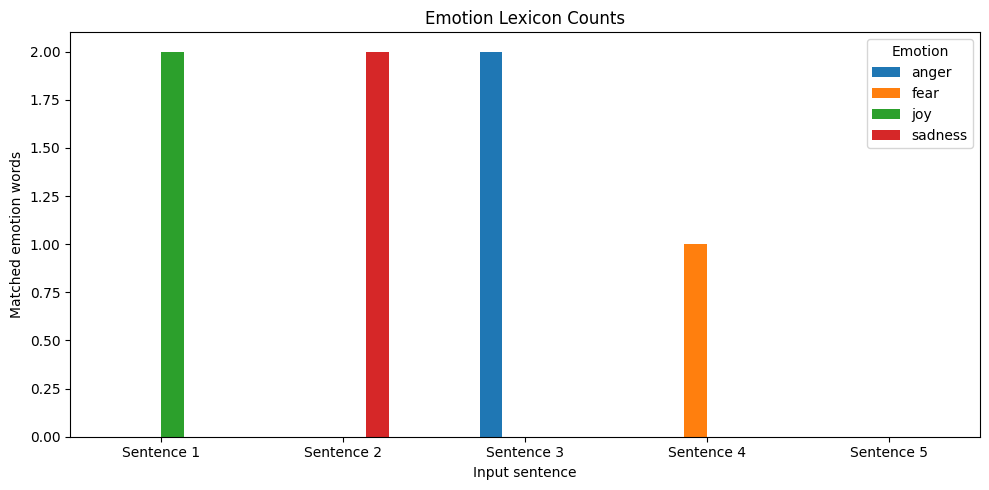

{'text': 'I am excited and happy, but a little nervous.', 'positive_count': 1, 'negative_count': 0, 'score': 1, 'sentiment': 'Positive', 'emotion_counts': {'joy': 2, 'sadness': 0, 'anger': 0, 'fear': 1}, 'detected_emotions': 'joy, fear'}


In [ ]:
# Visualize the number of lexicon matches for each emotion.
emotion_rows = []
for i, result in enumerate(results, start=1):
    for emotion, count in result["emotion_counts"].items():
        emotion_rows.append({"Sentence": f"Sentence {i}",
                             "Emotion": emotion, "Count": count})
emotion_df = pd.DataFrame(emotion_rows)
pivot = emotion_df.pivot(index="Sentence", columns="Emotion",
                         values="Count").fillna(0)
ax = pivot.plot(kind="bar", figsize=(10, 5))
ax.set_title("Emotion Lexicon Counts")
ax.set_xlabel("Input sentence")
ax.set_ylabel("Matched emotion words")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Test your own sentence.
print(analyze_sentiment_emotion(
    "I am excited and happy, but a little nervous."
))

**Result:** The program labels sentiment and detects emotion words, then visualizes emotion counts. To improve it, expand the lexicons, add negation handling (e.g. “not happy”), and evaluate on labelled test data.

---
# Assignment 3 – Machine Translation: Indian Language to English

This section uses **Meta NLLB-200 distilled 600M**, a pretrained encoder–decoder multilingual translation model supporting many Indian languages. English target code: `eng_Latn`. The first download is large; internet access is required and a GPU is recommended. Check the model card and license before use outside coursework.

In [ ]:
!pip install -q transformers sentencepiece torch

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

TRANSLATION_MODEL = "facebook/nllb-200-distilled-600M"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

translation_tokenizer = AutoTokenizer.from_pretrained(TRANSLATION_MODEL)
translation_model = AutoModelForSeq2SeqLM.from_pretrained(
    TRANSLATION_MODEL
).to(device)
translation_model.eval()
print("NLLB translation model loaded.")

Device: cuda


config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

... (5 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

NLLB translation model loaded.


In [ ]:
# Common NLLB language codes; choose the one matching the input language/script.
INDIAN_LANGUAGE_CODES = {
    "Assamese": "asm_Beng", "Bengali": "ben_Beng",
    "Gujarati": "guj_Gujr", "Hindi": "hin_Deva",
    "Kannada": "kan_Knda", "Malayalam": "mal_Mlym",
    "Marathi": "mar_Deva", "Nepali": "npi_Deva",
    "Odia": "ory_Orya", "Punjabi": "pan_Guru",
    "Sanskrit": "san_Deva", "Tamil": "tam_Taml",
    "Telugu": "tel_Telu", "Urdu": "urd_Arab"
}

def translate_to_english(text, source_language_code="hin_Deva",
                         max_input_length=512, max_new_tokens=128):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Enter a non-empty source sentence.")
    if source_language_code == "eng_Latn":
        raise ValueError("Choose an Indian-language source code.")
    translation_tokenizer.src_lang = source_language_code
    encoded = translation_tokenizer(
        text.strip(), return_tensors="pt",
        truncation=True, max_length=max_input_length
    ).to(device)
    english_id = translation_tokenizer.convert_tokens_to_ids("eng_Latn")
    if english_id is None or english_id == translation_tokenizer.unk_token_id:
        raise ValueError("Could not resolve NLLB English language token.")
    with torch.no_grad():
        generated = translation_model.generate(
            **encoded, forced_bos_token_id=english_id,
            max_new_tokens=max_new_tokens, num_beams=4
        )
    return translation_tokenizer.batch_decode(
        generated, skip_special_tokens=True
    )[0]

# Hindi example. Replace the sentence and source code for another language.
hindi_sentence = "नमस्ते, आप कैसे हैं?"
print("Input:", hindi_sentence)
print("English:", translate_to_english(hindi_sentence, "hin_Deva"))

Input: नमस्ते, आप कैसे हैं?


[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English: Hi, how are you?


In [ ]:
# Tamil example (runs the same pretrained model).
tamil_sentence = "வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?"
print("Input:", tamil_sentence)
print("English:", translate_to_english(tamil_sentence, "tam_Taml"))

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Input: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
English: Hi, how are you?


**Result:** The pretrained multilingual sequence-to-sequence model generates English from the selected Indian language. Language coverage and translation quality vary; verify important translations with a fluent speaker. Some language/script variants may require a different NLLB code.

---
# Assignment 4 – Task-Oriented College Chatbot

This rule-based chatbot demonstrates:
- **Intent recognition** for greetings, timings, admissions, library, courses, contact, thanks, and goodbye.
- **Dialogue state** storing the current intent and collected slots.
- **Slot filling**: if the user asks about courses without naming a department, the bot asks a follow-up and uses the next message as the course value.

Replace placeholder college details with verified information from your institution.

In [31]:
COLLEGE_INFO = {
    "college_name": "IFHE Hyderabad",
    "timings": "The college office is open from 9:00 AM to 5:00 PM, Monday to Friday.",
    "admissions": "For admission details, contact the admissions office or visit the official college website.",
    "library": "The library is open from 8:30 AM to 6:00 PM on working days. Carry your student ID.",
    "contact": "Please contact the college reception for the latest phone number and email.",
    "courses": {
        "computer science": "Computer Science covers programming, algorithms, databases, and software development.",
        "mechanical": "Mechanical Engineering covers design, manufacturing, and thermal systems.",
        "electronics": "Electronics covers circuits, communication systems, and embedded systems."
    }
}

INTENT_KEYWORDS = {
    "greeting": ["hello", "hi", "hey", "good morning", "good afternoon"],
    "timings": ["timing", "time", "open", "opening", "working hours", "office hours"],
    "admissions": ["admission", "apply", "application", "enroll", "enrol"],
    "library": ["library", "book", "borrow", "return"],
    "courses": ["course", "courses", "department", "program", "programme", "branch"],
    "contact": ["contact", "phone", "email", "address", "location"],
    "thanks": ["thank", "thanks", "thank you"],
    "goodbye": ["bye", "goodbye", "see you"]
}

def recognize_intent(message):
    text = message.lower()
    for intent, keywords in INTENT_KEYWORDS.items():
        for keyword in sorted(keywords, key=len, reverse=True):
            if re.search(r"\b" + re.escape(keyword) + r"\b", text):
                return intent
    return "unknown"

def extract_course(message):
    text = message.lower()
    for course in COLLEGE_INFO["courses"]:
        if course in text:
            return course
    return None

class CollegeChatbot:
    def __init__(self):
        self.reset_dialogue()

    def reset_dialogue(self):
        self.state = {"intent": None, "slots": {}, "awaiting_slot": None}

    def respond(self, message):
        if not isinstance(message, str) or not message.strip():
            return "Please enter a message so I can help."
        text = message.strip()
        lower = text.lower()

        if lower in {"reset", "start over", "restart"}:
            self.reset_dialogue()
            return "Conversation reset. How can I help?"

        # Fill the requested course slot from the next user message.
        if self.state["awaiting_slot"] == "course":
            course = extract_course(text)
            if course:
                self.state["slots"]["course"] = course
                self.state["awaiting_slot"] = None
                return COLLEGE_INFO["courses"][course]
            return "Please choose: " + ", ".join(COLLEGE_INFO["courses"]) + "."

        intent = recognize_intent(text)
        self.state["intent"] = intent

        if intent == "greeting":
            return f"Hello! Welcome to {COLLEGE_INFO['college_name']}. How can I help?"
        if intent == "timings":
            return COLLEGE_INFO["timings"]
        if intent == "admissions":
            return COLLEGE_INFO["admissions"]
        if intent == "library":
            return COLLEGE_INFO["library"]
        if intent == "contact":
            return COLLEGE_INFO["contact"]
        if intent == "courses":
            course = extract_course(text)
            if course:
                self.state["slots"]["course"] = course
                return COLLEGE_INFO["courses"][course]
            self.state["awaiting_slot"] = "course"
            return "Which department? Options: " + ", ".join(COLLEGE_INFO["courses"]) + "."
        if intent == "thanks":
            return "You're welcome! Anything else I can help with?"
        if intent == "goodbye":
            self.reset_dialogue()
            return "Goodbye! Have a great day."
        return ("I did not understand. Ask about admissions, timings, courses, "
                "the library, or contact information.")

bot = CollegeChatbot()
demo_messages = [
    "Hello", "What courses do you offer?", "Computer Science",
    "What are the library timings?", "Thank you"
]
for user_message in demo_messages:
    print("You:", user_message)
    print("Bot:", bot.respond(user_message))
    print("State:", bot.state)
    print("-" * 55)

You: Hello
Bot: Hello! Welcome to IFHE Hyderabad. How can I help?
State: {'intent': 'greeting', 'slots': {}, 'awaiting_slot': None}
-------------------------------------------------------
You: What courses do you offer?
Bot: Which department? Options: computer science, mechanical, electronics.
State: {'intent': 'courses', 'slots': {}, 'awaiting_slot': 'course'}
-------------------------------------------------------
You: Computer Science
Bot: Computer Science covers programming, algorithms, databases, and software development.
State: {'intent': 'courses', 'slots': {'course': 'computer science'}, 'awaiting_slot': None}
-------------------------------------------------------
You: What are the library timings?
Bot: The library is open from 8:30 AM to 6:00 PM on working days. Carry your student ID.
State: {'intent': 'library', 'slots': {'course': 'computer science'}, 'awaiting_slot': None}
-------------------------------------------------------
You: Thank you
Bot: You're welcome! Anything 

In [34]:
# Optional interactive loop. Run this cell and type 'quit' to stop.
interactive_bot = CollegeChatbot()
print("College chatbot ready. Type 'quit' to stop or 'reset' to restart.")
while True:
    user_input = input("You: ").strip()
    if user_input.lower() == "quit":
        print("Bot: Goodbye!")
        break
    print("Bot:", interactive_bot.respond(user_input))

College chatbot ready. Type 'quit' to stop or 'reset' to restart.
You: hi
Bot: Hello! Welcome to IFHE Hyderabad. How can I help?
You: library
Bot: The library is open from 8:30 AM to 6:00 PM on working days. Carry your student ID.
You: thank you
Bot: You're welcome! Anything else I can help with?
You: quit
Bot: Goodbye!


**Result:** The chatbot answers common college questions, remembers its dialogue state, and asks for a missing course slot. This is a baseline; a real deployment needs verified institutional data, broader training examples, robust entity extraction, and a human-contact fallback.

---
# Assignment 5 – Automatic Speech Recognition (ASR) and Log-Mel Spectrogram

This section uses **OpenAI Whisper small** through Hugging Face Transformers. Whisper is multilingual and can transcribe English and many Indian languages. Language detection is automatic unless a language hint is supplied.

Use a local WAV, MP3, or M4A file. Clear audio with limited background noise gives better results. Model weights download on first use; internet is required.

In [ ]:
!pip install -q transformers accelerate librosa soundfile sentencepiece

In [27]:
import os
import torch
import librosa
import librosa.display
import matplotlib.pyplot as plt
from transformers import pipeline

ASR_MODEL = "openai/whisper-small"
asr_device = 0 if torch.cuda.is_available() else -1
asr_pipeline = pipeline(
    "automatic-speech-recognition",
    model=ASR_MODEL,
    device=asr_device,
    chunk_length_s=30
)
print("Whisper loaded on", "GPU" if asr_device == 0 else "CPU")

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on its own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).


Whisper loaded on GPU


In [28]:
# Upload/copy an audio file into the notebook directory and set its path here.
AUDIO_PATH = "/content/AUD-20261106-WA0014.aac"

def transcribe_audio(audio_path, language=None):
    if not os.path.isfile(audio_path):
        raise FileNotFoundError(
            f"Audio file not found: {audio_path}. Upload an audio file and update AUDIO_PATH."
        )
    generation_options = {}
    if language:
        generation_options["language"] = language
    output = asr_pipeline(
        audio_path,
        generate_kwargs=generation_options,
        return_timestamps=False
    )
    return output["text"].strip()

# After setting AUDIO_PATH to a real audio file, run:
# print("Transcript:", transcribe_audio(AUDIO_PATH))
# Optional language hint examples: "hindi", "tamil", "telugu", "english"
# print("Transcript:", transcribe_audio(AUDIO_PATH, language="hindi"))

### Log-Mel spectrogram feature extraction

A Mel spectrogram maps audio energy onto perceptually spaced frequency bands. The logarithm compresses its dynamic range. Here, Librosa computes an 80-band log-Mel spectrogram from mono audio resampled to 16 kHz.

In [29]:
def plot_log_mel_spectrogram(audio_path, sample_rate=16000,
                             n_mels=80, n_fft=400, hop_length=160):
    if not os.path.isfile(audio_path):
        raise FileNotFoundError(
            f"Audio file not found: {audio_path}. Update AUDIO_PATH first."
        )
    waveform, sr = librosa.load(audio_path, sr=sample_rate, mono=True)
    if waveform.size == 0:
        raise ValueError("Audio file contains no readable samples.")

    mel_power = librosa.feature.melspectrogram(
        y=waveform, sr=sample_rate, n_fft=n_fft,
        hop_length=hop_length, n_mels=n_mels, power=2.0
    )
    log_mel = librosa.power_to_db(mel_power, ref=np.max)

    plt.figure(figsize=(12, 5))
    librosa.display.specshow(
        log_mel, sr=sample_rate, hop_length=hop_length,
        x_axis="time", y_axis="mel"
    )
    plt.colorbar(format="%+2.0f dB", label="Power (dB)")
    plt.title("Log-Mel Spectrogram")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Mel frequency")
    plt.tight_layout()
    plt.show()

    print("Sample rate:", sample_rate, "Hz")
    print("Duration:", round(len(waveform) / sample_rate, 2), "seconds")
    print("Log-Mel feature shape:", log_mel.shape)
    return log_mel

# After setting AUDIO_PATH to a real audio file, run:
# log_mel_features = plot_log_mel_spectrogram(AUDIO_PATH)

[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece token

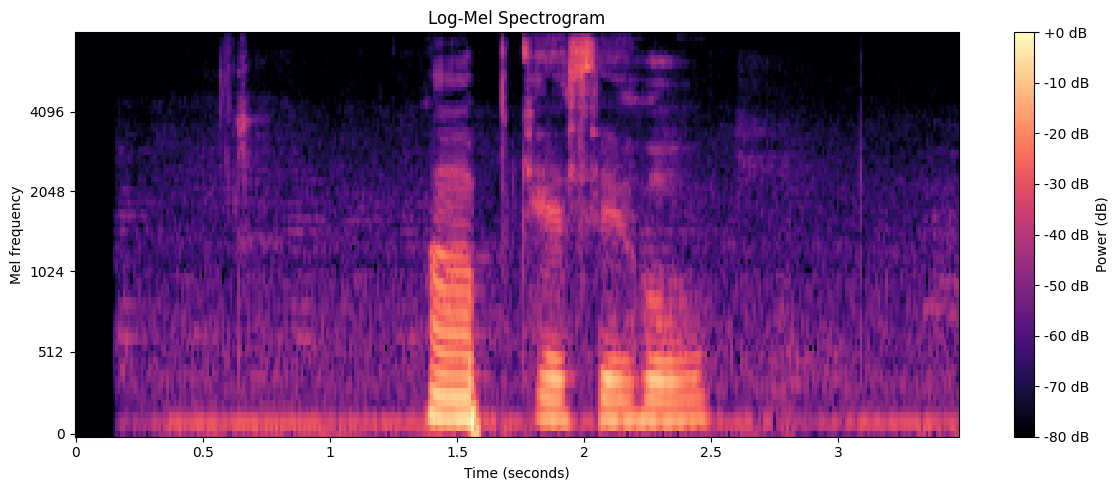

Sample rate: 16000 Hz
Duration: 3.48 seconds
Log-Mel feature shape: (80, 348)
Final transcript: Ah, qu'est-ce qu'il y a là ?


In [30]:
# Run ASR and feature extraction together after setting AUDIO_PATH:
recognized_text = transcribe_audio(AUDIO_PATH)
log_mel_features = plot_log_mel_spectrogram(AUDIO_PATH)
print("Final transcript:", recognized_text)

**Result:** Whisper returns a speech transcript, and Librosa computes and displays log-Mel features.

**Notes:** The first model run downloads weights. If CPU speed or memory is a problem, use `openai/whisper-tiny`. The plotted Librosa features are for visualization and are not claimed to be the exact internal Whisper feature tensor.

---
# Final Summary

| Assignment | Technique | Expected output |
|---|---|---|
| 1. Sentence similarity and word associations | TF–IDF, cosine similarity, PMI, PPMI | Similarity matrix and word-pair ranking |
| 2. Sentiment and emotion detection | Lexicons | Sentiment labels, emotion counts, chart |
| 3. Machine translation | NLLB-200 encoder–decoder model | Indian-language input translated into English |
| 4. Task-oriented chatbot | Intent recognition, state, slot filling | Multi-turn college enquiry responses |
| 5. ASR | Whisper and Librosa log-Mel | Speech transcript and spectrogram |